In [8]:
# Data manipulation
import numpy as np
import pandas as pd

# Sparse matrix handling
from scipy.sparse import load_npz, save_npz

# Machine learning models
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Model serialization
import joblib

# Utilities
from pathlib import Path
import time

print("Libraries imported successfully!")

Libraries imported successfully!


In [7]:
# Load the paths
DATA_DIR = Path("../data/processed")
MODEL_DIR = Path("../models")
FEATURE_DIR = MODEL_DIR / "feature_selection"

# Load the feature matrices
X_train = load_npz(FEATURE_DIR / "encoded_features.npz")
X_test = load_npz(FEATURE_DIR / "encoded_test_features.npz")

# Load the target labels
y_train = pd.read_csv(FEATURE_DIR / "y_train.csv").squeeze()
y_test = pd.read_csv(FEATURE_DIR / "y_test.csv").squeeze()

In [11]:
# Train Test Split
X_train_final, X_val, y_train_final, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

In [12]:
print("Training set:", X_train_final.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

print("\nTraining labels:")
print(y_train_final.value_counts(normalize=True) * 100)

print("\nValidation labels:")
print(y_val.value_counts(normalize=True) * 100)

Training set: (69557, 81301)
Validation set: (17390, 81301)
Test set: (21737, 81301)

Training labels:
y_train
0    55.804592
1    44.195408
Name: proportion, dtype: float64

Validation labels:
y_train
0    55.802185
1    44.197815
Name: proportion, dtype: float64


In [13]:
# Now, train a base model, here, we use logistic regression
from sklearn.linear_model import LogisticRegression
baseline_model = LogisticRegression(max_iter=1000, class_weight='balanced',random_state=42)

In [14]:
start_time = time.time()

baseline_model.fit(X_train_final, y_train_final)

training_time = time.time() - start_time
print(f"Training time: {training_time:.2f} seconds")

Training time: 3.18 seconds


In [15]:
y_val_pred = baseline_model.predict(X_val)

In [16]:
# Evaluate the model
print("Logistic Regression - Baseline Results")
print("--------------------------------------")

print("Accuracy:", accuracy_score(y_val, y_val_pred))
print("Precision:", precision_score(y_val, y_val_pred))
print("Recall:", recall_score(y_val, y_val_pred))
print("F1 Score:", f1_score(y_val, y_val_pred))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred))

Logistic Regression - Baseline Results
--------------------------------------
Accuracy: 0.9916618746405981
Precision: 0.9879642810922739
Recall: 0.9932344522508457
F1 Score: 0.9905923571011483

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      9704
           1       0.99      0.99      0.99      7686

    accuracy                           0.99     17390
   macro avg       0.99      0.99      0.99     17390
weighted avg       0.99      0.99      0.99     17390



In [17]:
y_train_pred = baseline_model.predict(X_train_final)

print("TRAINING PERFORMANCE")
print("--------------------")
print("Accuracy:", accuracy_score(y_train_final, y_train_pred))
print("Precision:", precision_score(y_train_final, y_train_pred))
print("Recall:", recall_score(y_train_final, y_train_pred))
print("F1 Score:", f1_score(y_train_final, y_train_pred))

print("\nVALIDATION PERFORMANCE")
print("----------------------")
print("Accuracy:", accuracy_score(y_val, y_val_pred))
print("Precision:", precision_score(y_val, y_val_pred))
print("Recall:", recall_score(y_val, y_val_pred))
print("F1 Score:", f1_score(y_val, y_val_pred))

TRAINING PERFORMANCE
--------------------
Accuracy: 0.9967796195925643
Precision: 0.9953575950394442
Recall: 0.9973650824631599
F1 Score: 0.9963603275705186

VALIDATION PERFORMANCE
----------------------
Accuracy: 0.9916618746405981
Precision: 0.9879642810922739
Recall: 0.9932344522508457
F1 Score: 0.9905923571011483


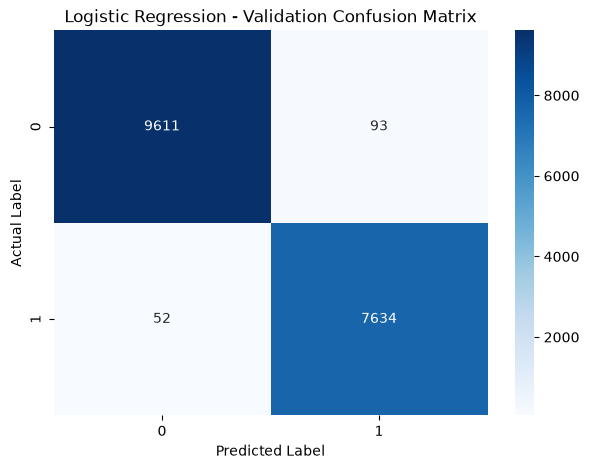

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
cm = confusion_matrix(y_val, y_val_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Logistic Regression - Validation Confusion Matrix")

plt.show()

### Multinomial Naive Bayes Model 

In [22]:
# Train Multinomial Naive Bayes model
nb_model = MultinomialNB()

In [23]:
start_time = time.time()

nb_model.fit(
    X_train_final,
    y_train_final
)

training_time = time.time() - start_time

print(f"Training time: {training_time:.2f} seconds")

Training time: 0.08 seconds


In [24]:
y_val_pred_nb = nb_model.predict(X_val)

In [25]:
print("Multinomial Naive Bayes - Validation Results")
print("--------------------------------------------")

print("Accuracy:", accuracy_score(y_val, y_val_pred_nb))
print("Precision:", precision_score(y_val, y_val_pred_nb))
print("Recall:", recall_score(y_val, y_val_pred_nb))
print("F1 Score:", f1_score(y_val, y_val_pred_nb))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_nb))

Multinomial Naive Bayes - Validation Results
--------------------------------------------
Accuracy: 0.9783208740655549
Precision: 0.9791530090468074
Recall: 0.9716367421285454
F1 Score: 0.9753803957421798

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98      9704
           1       0.98      0.97      0.98      7686

    accuracy                           0.98     17390
   macro avg       0.98      0.98      0.98     17390
weighted avg       0.98      0.98      0.98     17390



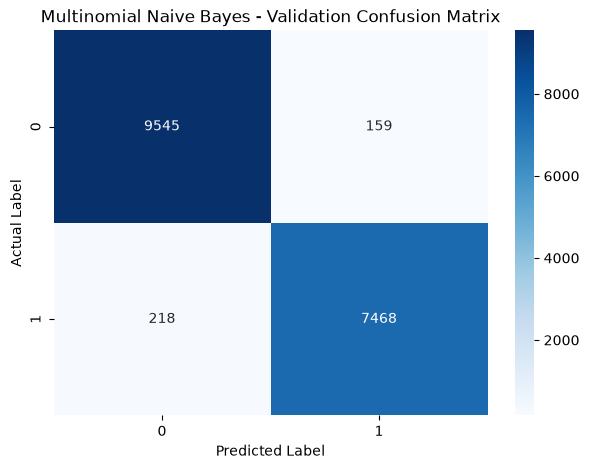

In [35]:
cm_nb = confusion_matrix(y_val, y_val_pred_nb)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Multinomial Naive Bayes - Validation Confusion Matrix")

plt.show()

### Support Vector Machine

In [30]:
from sklearn.svm import LinearSVC
svm_model = LinearSVC(class_weight='balanced', random_state=42, max_iter=2000)

In [31]:
start_time = time.time()

svm_model.fit(X_train_final, y_train_final)

training_time = time.time() - start_time

print(f"Training time: {training_time:.2f} seconds")

Training time: 2.23 seconds


In [32]:
y_val_pred_svm = svm_model.predict(X_val)

In [33]:
print("Linear SVM - Validation Results")
print("--------------------------------")

print("Accuracy:", accuracy_score(y_val, y_val_pred_svm))
print("Precision:", precision_score(y_val, y_val_pred_svm))
print("Recall:", recall_score(y_val, y_val_pred_svm))
print("F1 Score:", f1_score(y_val, y_val_pred_svm))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_svm))

Linear SVM - Validation Results
--------------------------------
Accuracy: 0.9948246118458884
Precision: 0.9929906542056075
Recall: 0.9953161592505855
F1 Score: 0.9941520467836257

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00      9704
           1       0.99      1.00      0.99      7686

    accuracy                           0.99     17390
   macro avg       0.99      0.99      0.99     17390
weighted avg       0.99      0.99      0.99     17390



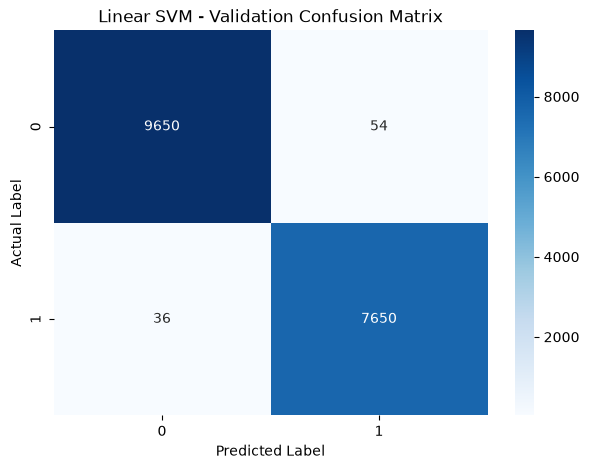

In [34]:
cm_svm = confusion_matrix(y_val, y_val_pred_svm)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Linear SVM - Validation Confusion Matrix")

plt.show()

In [36]:
model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Multinomial Naive Bayes",
        "Linear SVM"
    ],
    "Accuracy": [
        accuracy_score(y_val, y_val_pred),
        accuracy_score(y_val, y_val_pred_nb),
        accuracy_score(y_val, y_val_pred_svm)
    ],
    "Precision": [
        precision_score(y_val, y_val_pred),
        precision_score(y_val, y_val_pred_nb),
        precision_score(y_val, y_val_pred_svm)
    ],
    "Recall": [
        recall_score(y_val, y_val_pred),
        recall_score(y_val, y_val_pred_nb),
        recall_score(y_val, y_val_pred_svm)
    ],
    "F1 Score": [
        f1_score(y_val, y_val_pred),
        f1_score(y_val, y_val_pred_nb),
        f1_score(y_val, y_val_pred_svm)
    ],
    "Training Time (s)": [
        3.18, 0.08, 2.23
    ]
})

model_results = model_results.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

model_results

,Model,Accuracy,Precision,Recall,F1 Score,Training Time (s)
0,Linear SVM,0.994825,0.992991,0.995316,0.994152,2.23
1,Logistic Regression,0.991662,0.987964,0.993234,0.990592,3.18
2,Multinomial Naive Bayes,0.978321,0.979153,0.971637,0.975380,0.08


In [39]:
from sklearn.linear_model import SGDClassifier
sgd_model = SGDClassifier(
    loss="hinge",
    penalty="l2",
    alpha=0.0001,
    max_iter=1000,
    tol=1e-3,
    class_weight="balanced",
    random_state=42
)

In [40]:
start_time = time.time()

sgd_model.fit(
    X_train_final,
    y_train_final
)

sgd_training_time = time.time() - start_time

print(f"SGD Training Time: {sgd_training_time:.2f} seconds")

SGD Training Time: 0.43 seconds


In [41]:
y_val_pred_sgd = sgd_model.predict(X_val)

In [42]:
print("SGD Classifier - Validation Results")
print("-----------------------------------")

print("Accuracy:", accuracy_score(y_val, y_val_pred_sgd))
print("Precision:", precision_score(y_val, y_val_pred_sgd))
print("Recall:", recall_score(y_val, y_val_pred_sgd))
print("F1 Score:", f1_score(y_val, y_val_pred_sgd))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_sgd))

SGD Classifier - Validation Results
-----------------------------------
Accuracy: 0.9928694652098907
Precision: 0.9902748962655602
Recall: 0.9936247723132969
F1 Score: 0.9919470061046889

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      9704
           1       0.99      0.99      0.99      7686

    accuracy                           0.99     17390
   macro avg       0.99      0.99      0.99     17390
weighted avg       0.99      0.99      0.99     17390



Confusion Matrix for SGD Classifier:
[[9629   75]
 [  49 7637]]


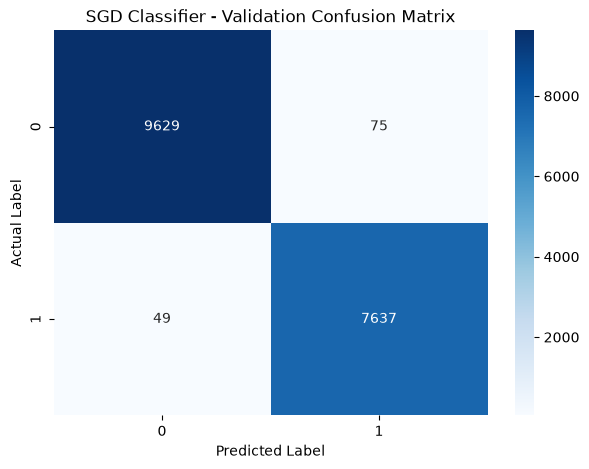

In [45]:
cm_sgd = confusion_matrix(y_val, y_val_pred_sgd)
print('Confusion Matrix for SGD Classifier:')
print(cm_sgd)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_sgd,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("SGD Classifier - Validation Confusion Matrix")

plt.show()

In [44]:
# Save SGD Classifier
sgd_model_path = MODEL_DIR / "sgd_classifier.joblib"

joblib.dump(sgd_model, sgd_model_path)

print("SGD Classifier saved successfully!")
print(f"Location: {sgd_model_path}")

SGD Classifier saved successfully!
Location: ..\models\sgd_classifier.joblib


In [49]:
### Now, save the model reports
REPORTS_DIR = Path("../reports")
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Validation metrics
metrics = {
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Score": [
        0.992,
        0.990,
        0.993,
        0.991
    ]
}

metrics_df = pd.DataFrame(metrics)

# Save as CSV
metrics_df.to_csv(
    REPORTS_DIR / "sgd_classifier_validation_results.csv",
    index=False
)

print("Validation results saved successfully!")

Validation results saved successfully!


In [48]:
# Save the confusion matrix as a csv file
confusion_matrix = [
    [9629, 75],
    [49, 7637]
]

cm_df = pd.DataFrame(
    confusion_matrix,
    index=["Actual_0", "Actual_1"],
    columns=["Predicted_0", "Predicted_1"]
)

cm_df.to_csv(
    REPORTS_DIR / "sgd_classifier_confusion_matrix.csv"
)

print("Confusion matrix saved successfully!")

Confusion matrix saved successfully!
